# Mini Project 3: Iris Flower Clustering

## Objective
Build an unsupervised machine learning model using K-Means to cluster Iris flowers into three groups.

## Dataset
The Iris dataset from Scikit-learn.

## Project Tasks
1. Load and explore the dataset.
2. Standardize the input features.
3. Apply K-Means clustering with three clusters.
4. Visualize the predicted clusters.
5. Compare predicted clusters with actual species labels.
6. Evaluate the clustering results using the Adjusted Rand Index.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("Dataset shape:", X.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nSpecies names:")
print(iris.target_names)

print("\nFirst five rows:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

Dataset shape: (150, 4)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Species names:
['setosa' 'versicolor' 'virginica']

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (150, 4)


In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print("First 20 predicted cluster labels:")
print(clusters[:20])

print("\nNumber of flowers in each cluster:")
print(pd.Series(clusters).value_counts().sort_index())

First 20 predicted cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Number of flowers in each cluster:
0    53
1    50
2    47
Name: count, dtype: int64


C:\Users\pc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [6]:
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns
)

print("Cluster centers in original feature units:")
print(centers.round(2))

Cluster centers in original feature units:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0               5.80              2.67               4.37              1.41
1               5.01              3.43               1.46              0.25
2               6.78              3.10               5.51              1.97


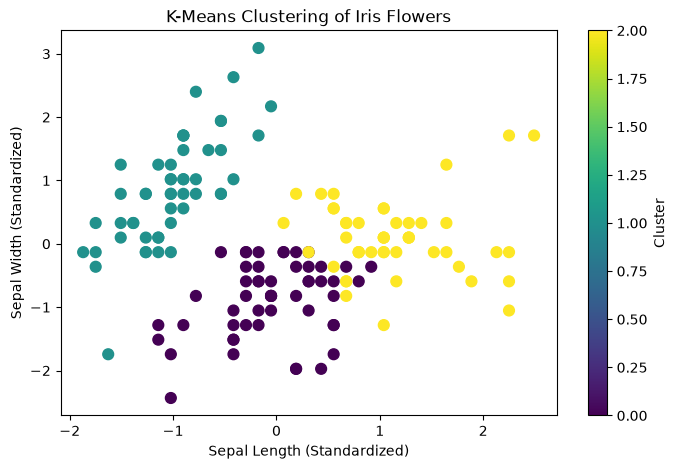

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=60
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("K-Means Clustering of Iris Flowers")
plt.colorbar(label="Cluster")
plt.show()

In [8]:
comparison = pd.DataFrame({
    "Actual Species": iris.target_names[y],
    "Predicted Cluster": clusters
})

print("First 10 comparisons:")
print(comparison.head(10))

print("\nActual Species vs Predicted Clusters:")
print(pd.crosstab(
    comparison["Actual Species"],
    comparison["Predicted Cluster"]
))

First 10 comparisons:
  Actual Species  Predicted Cluster
0         setosa                  1
1         setosa                  1
2         setosa                  1
3         setosa                  1
4         setosa                  1
5         setosa                  1
6         setosa                  1
7         setosa                  1
8         setosa                  1
9         setosa                  1

Actual Species vs Predicted Clusters:
Predicted Cluster   0   1   2
Actual Species               
setosa              0  50   0
versicolor         39   0  11
virginica          14   0  36


In [9]:
ari = adjusted_rand_score(y, clusters)

print("Adjusted Rand Index (ARI):", round(ari, 3))

Adjusted Rand Index (ARI): 0.62


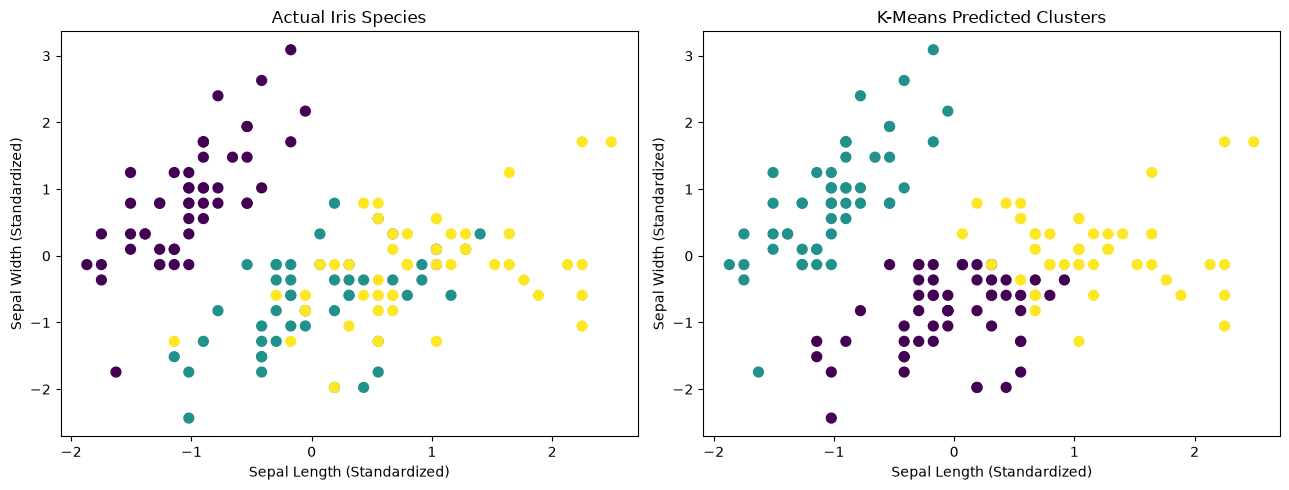

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap="viridis",
    s=50
)
axes[0].set_title("Actual Iris Species")
axes[0].set_xlabel("Sepal Length (Standardized)")
axes[0].set_ylabel("Sepal Width (Standardized)")

axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)
axes[1].set_title("K-Means Predicted Clusters")
axes[1].set_xlabel("Sepal Length (Standardized)")
axes[1].set_ylabel("Sepal Width (Standardized)")

plt.tight_layout()
plt.show()

## Conclusion

In this project, K-Means clustering was applied to the Iris dataset to group flowers into three clusters. The input features were standardized before training the model. The resulting clusters were visualized using scatter plots and compared with the actual Iris species labels using a cross-tabulation and the Adjusted Rand Index. The experiment demonstrates how unsupervised learning can identify patterns in data without using class labels during training. Some overlap between species may occur because K-Means groups flowers according to feature similarity rather than known species categories.